# Fit a smooth on the sphere

Latitude and longitude describe a sphere with a connected longitude seam and shared poles. We simulate global coverage and fit a spherical spline using latitude and longitude in degrees.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Generate globally distributed locations

Sampling longitude uniformly and sine of latitude uniformly gives broad coverage without concentrating observations at the poles.

In [2]:
longitude=rng.uniform(-180,180,600)
latitude=np.rad2deg(np.arcsin(rng.uniform(-1,1,600)))
def truth(la,lo):return np.cos(np.deg2rad(la))*np.sin(np.deg2rad(lo))+.4*np.sin(np.deg2rad(la))
data=pd.DataFrame({"latitude":latitude,"longitude":longitude,"y":truth(latitude,longitude)+rng.normal(0,.12,len(latitude))})
train,test=train_test_split(data,test_size=.25,random_state=109)
model=GAM(formula="y ~ s(latitude,longitude,bs='sos',k=40)",optimize_smoothing=True,smoothing_method="reml").fit(train)

## Inspect the global surface and seam

We plot an equirectangular map for readability. The spherical basis, not this display projection, defines neighborhood geometry. Seam rows at -180 and 180 degrees should agree; longitude should become irrelevant at a pole.

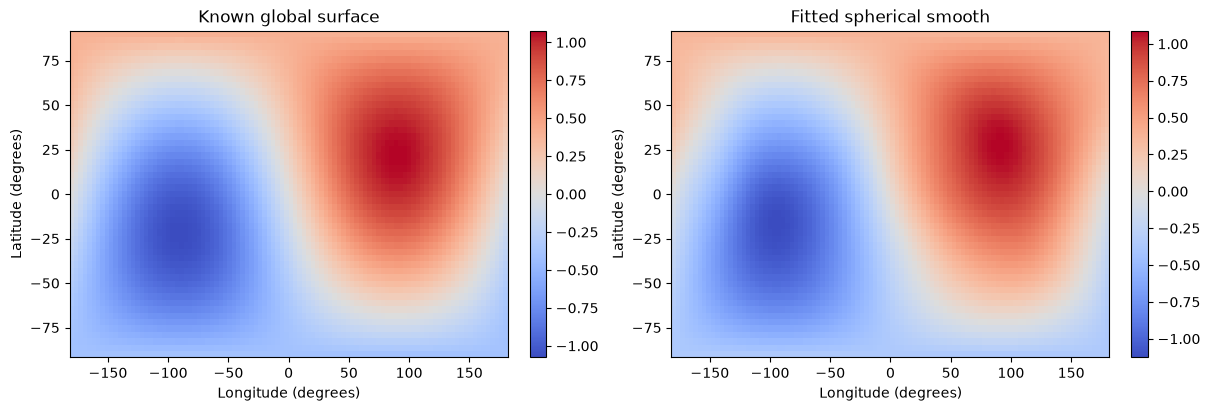

Check,Value
Maximum seam difference,0.000000
North pole longitude range,0.000000
South pole longitude range,0.000000
Test RMSE,0.117034


In [3]:
longitude_grid,latitude_grid=np.meshgrid(np.linspace(-180,180,100),np.linspace(-90,90,51))
grid=pd.DataFrame({"latitude":latitude_grid.ravel(),"longitude":longitude_grid.ravel()})
prediction=model.predict(grid).reshape(latitude_grid.shape)
figure,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for axis,surface,title in zip(axes,[truth(latitude_grid,longitude_grid),prediction],["Known global surface","Fitted spherical smooth"]):
    image=axis.pcolormesh(longitude_grid,latitude_grid,surface,shading="auto",cmap="coolwarm")
    figure.colorbar(image,ax=axis)
    axis.set(title=title,xlabel="Longitude (degrees)",ylabel="Latitude (degrees)")
plt.show()
plt.close(figure)
pd.DataFrame({"Check":["Maximum seam difference","North pole longitude range","South pole longitude range","Test RMSE"],"Value":[np.max(np.abs(prediction[:,0]-prediction[:,-1])),np.ptp(prediction[-1]),np.ptp(prediction[0]),mean_squared_error(test.y,model.predict(test))**.5]}).style.hide(axis="index").format({"Value":"{:.6f}"})

The seam and pole differences round to zero at six decimal places, and test RMSE is 0.117. These geometric checks complement the global surface comparison; they do not replace prediction assessment.